# Scan parameters: what changes the splat

How the scan pipeline's settings change the result on one real phone clip, `data/raw/setup_01/bowl_1angle.mp4`: a white bowl on a wooden floor, one 25 s lap at roughly constant height.

- **Modules:** `hurobo.scan` (`SfmOptions`, `SfmReconstructor`, `SplatTrainer`, `orbit_coverage_deg`), `hurobo.scan_sweep` (`ScanSweep`, `sweep_table`), `hurobo.scan_crop` (`estimate_object_crop`, `locate_white_object`, `crop_report`), `hurobo.utils.viewer` (`sweep_figure`, `sfm_figure`, `crop_figure`)
- **Data:** real clip, not committed. This notebook only *reads* the stored sweep in `data/scans/sweeps/bowl_1angle/`. To redo it (about 30 min with a GPU):
  `uv run python scripts/14_scan_param_sweep.py data/raw/setup_01/bowl_1angle.mp4 --name bowl_1angle`
- **Setup:** one run per config, one seed, 7000 training iterations unless stated, every 10th registered keyframe withheld and used to score the splat. The sweep splats are not cropped; the second half of the notebook compares three ways of cropping them.

In [ ]:
%load_ext autoreload
%autoreload 2

In [1]:
from hurobo.utils.notebook import setup_notebook

ROOT = setup_notebook()  # chdir to the repo root and set MUJOCO_GL=egl

## The configs
`colmap_defaults` is what `scripts/09_scan_object.py` does today. Each following row changes one thing, until `low_threshold_exhaustive` which combines the two SfM changes, and then two variations of that.

In [2]:
from hurobo.scan_sweep import ScanSweep, sweep_table

results = ScanSweep.load(ROOT / "data/scans/sweeps/bowl_1angle")
sweep_table(results).set_index("config").T

config,colmap_defaults,low_sift_threshold,exhaustive_matching,low_threshold_exhaustive,sparse_keyframes_40,train_30k
matching,sequential,sequential,exhaustive,exhaustive,exhaustive,exhaustive
SIFT threshold,default,0.002,default,0.002,0.002,0.002
frames,120,120,120,120,40,120
spacing (s),0.19,0.19,0.19,0.19,0.58,0.19
iterations,7000,7000,7000,7000,7000,30000
registered,39/120,120/120,53/120,120/120,40/40,120/120
registered %,32,100,44,100,100,100
orbit covered (deg),180,349,214,349,142,349
models,3,1,2,1,1,1
SfM points,2867,16702,3590,23187,2599,23187


## Registration, coverage and PSNR
Read the top two panels before the PSNR. PSNR is measured only on keyframes that registered, so a config that reconstructs a short arc is scored on easy neighbouring views: `colmap_defaults` has the *highest* held-out PSNR of the sweep while using 39 of 120 frames split over three disconnected models. Orbit coverage is approximate for fragments (see `orbit_coverage_deg`).

In [3]:
from hurobo.utils.viewer import sweep_figure

sweep_figure(results, title="bowl_1angle: scan parameter sweep").show()

## The cameras COLMAP recovered
Same clip, same keyframes. Left: COLMAP's defaults reconstruct a fragment of the lap (the largest of three disconnected models). Right: with a lower SIFT contrast threshold every keyframe registers in one model and the cameras close the loop. Points are subsampled.

In [4]:
from hurobo.utils.viewer import sweep_cameras_figure

by_name = {r.config.name: r for r in results}
sweep_cameras_figure(by_name["colmap_defaults"], title="colmap_defaults", every_nth_point=4).show()
sweep_cameras_figure(by_name["low_sift_threshold"], title="low_sift_threshold", every_nth_point=4).show()

## Held-out views: photo (left) vs splat (right)
Four views each config never trained on. These are neighbours of training views along the same path, so this is interpolation along the lap, not novel viewpoints.

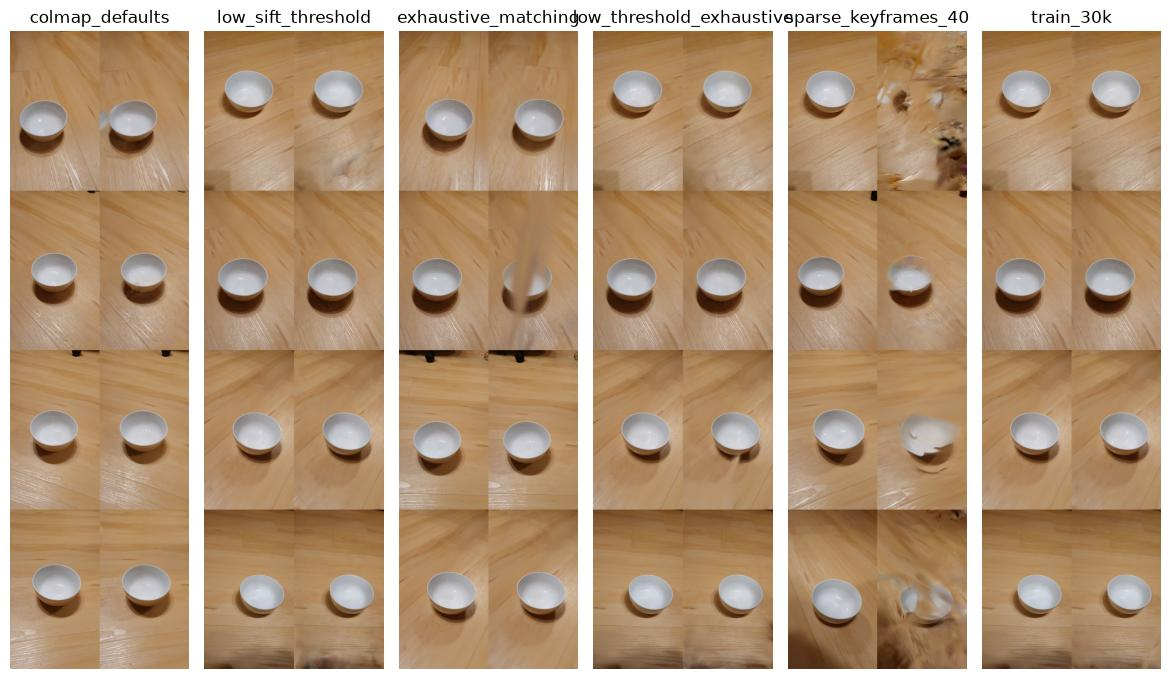

In [5]:
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

from hurobo.utils.plotting import plot_image_row

set_matplotlib_formats("jpeg")  # photos as JPEG keep the stored notebook small
plot_image_row({r.config.name: plt.imread(r.preview_path) for r in results}, height_in=7)

## The splats in 3D
Each splat rasterised with gsplat from 12 cameras orbiting its centre (full Gaussians, not just centres). Drag the slider to orbit. The splats are uncropped, so the floor and everything COLMAP triangulated around the bowl is in the view; for `colmap_defaults` that is only the fragment of the lap it registered.

In [6]:
from hurobo.splat import render_splat_orbit
from hurobo.utils.viewer import orbit_figure

for name in ["colmap_defaults", "low_threshold_exhaustive"]:
    views = render_splat_orbit(by_name[name].ply_path, num_views=12, image_size=384)
    orbit_figure(views, title=f"Rendered splat: {name}").show()

## What this shows (and what it does not)

1. **On this clip the SIFT contrast threshold is what decides registration.** COLMAP's default (0.0067) found ~500 features per frame on the smooth bowl and low-contrast floor and registered 39/120 frames in three models. Lowering it to 0.002 (with a looser ratio test of 0.9) registered 120/120 in one model with 6x the sparse points.
2. **Exhaustive matching did not help once the threshold was lowered.** With default thresholds it reached only 53/120; with the lower threshold sequential and exhaustive both give 120/120, but exhaustive SfM took 376 s against 70 s. That is specific to this clip: the 3-angle clip registered only 70/120 in three models with the lower threshold and sequential matching, and the exhaustive retry (now automatic in `SfmReconstructor.robust`) reached 120/120 (see the end-to-end section below).
3. **PSNR alone rewards the broken scan.** `colmap_defaults` scores 33.1 dB held-out, above every fixed config (31.6-32.0 dB), because its test views lie inside a ~180 degree fragment. Check registered fraction and orbit coverage first.
4. **More training buys memorisation, not unseen-view quality.** 30k iterations vs 7k: training PSNR +2.4 dB, held-out +0.4 dB, 4.2x the Gaussians (713k vs 168k) and 5.6x the time. The train-to-held-out gap grows from 1.9 to 3.9 dB.
5. **Sparser keyframes hurt a lot, and the held-out strip shows why PSNR is not the whole story.** 40 frames (one per 0.58 s) registered 40/40 but with 2.6k points, 1.05 px reprojection error and 21.3 dB held-out, about 10 dB below the 0.19 s spacing; its renders are visibly torn and full of floaters. In the other direction, `exhaustive_matching` scores 32.4 dB yet has a floater streak across the bowl in its second held-out view.

**Limits.** One clip, one run per config, one seed: differences of a few tenths of a dB (for example 31.6 vs 32.0) cannot be ranked. Held-out sets are small (12 views for the 120-frame configs, 4 for the others), so the 40-frame number is especially noisy; a different scratch run that strided 40 of the already-registered frames scored 27.4 dB, so the size of that drop depends on how the frames are chosen, though its direction did not change. Held-out views neighbour training views along the same lap, so none of this measures novel viewpoints, and the PSNR is dominated by floor pixels rather than the bowl.

## Cropping the object: three methods
A scan of a bowl on a floor contains the floor, the room and floaters; the object has to be cut out. Three ways, all applied to the same uncropped splat (`low_sift_threshold`, 120/120 registered):

1. **current** (`CropCylinder.around_points`): a cylinder around the 95th-percentile radius of *all* SfM points. Built for a turntable on a plain backdrop, where the points sit on the object.
2. **floor + cluster** (`estimate_object_crop`): RANSAC fits the floor plane, the points standing above it inside the camera ring are clustered, and the largest cluster is the object.
3. **explicit** (`--crop X Y R`): centre and radius typed in after looking at the preview below.

To judge them without trusting any of them, the bowl is also located **independently**: its white pixels are triangulated across the keyframes (`locate_white_object`). That reference works only because the bowl is the one white thing in view, and the pipeline never uses it. Its ray residual below says how sure it is.

In [7]:
import numpy as np

from hurobo.scan import CropCylinder, object_frame_from_orbit
from hurobo.scan_crop import crop_report, estimate_object_crop, locate_white_object

sweep_result = by_name["low_sift_threshold"]
sfm = sweep_result.load_sfm(with_pixels=True)
sfm_obj = sfm.in_frame(object_frame_from_orbit(sfm))  # object frame, the one the splat is trained in

reference = locate_white_object(sfm_obj)
estimate = estimate_object_crop(sfm_obj.points_world, sfm_obj.camera_centres_world)
methods = {
    "1 current: percentile of all points": CropCylinder.around_points(sfm_obj.points_world),
    "2 floor + cluster (RANSAC)": estimate.cylinder,
    "3 explicit (typed in)": CropCylinder(2.6, -0.3, 2.5, np.array([-0.1, 0.6])),
}
print(
    f"reference: centre {np.round(reference.centre, 2)}, radius {reference.radius:.2f} "
    f"from {reference.num_views}/{len(sfm_obj.images)} views, ray residual {reference.mean_ray_distance:.2f}"
)
print(
    f"floor: {estimate.floor.inlier_fraction:.0%} of points on the plane, "
    f"tilt {estimate.floor.tilt_deg:.1f} deg; "
    f"camera ring radius {estimate.ring_radius:.2f}; cluster {estimate.num_cluster_points} of "
    f"{estimate.num_candidates} candidate points"
)
crop_report(methods, reference, sweep_result.ply_path)

reference: centre [-0.09  0.65  0.89], radius 1.22 from 68/120 views, ray residual 0.19
floor: 44% of points on the plane, tilt 1.1 deg; camera ring radius 3.70; cluster 808 of 814 candidate points


,method,radius / object radius,centre off (object radii),object inside,Gaussians kept (%)
0,1 current: percentile of all points,7.4,0.54,True,42.5
1,2 floor + cluster (RANSAC),2.2,0.18,True,37.8
2,3 explicit (typed in),2.1,0.04,True,37.5


### The crops in 3D
Sparse points, the three cylinders and the RANSAC floor. The white-pixel reference is drawn as the small cylinder. Drag to rotate; click legend entries to hide a cylinder.

In [8]:
from hurobo.utils.viewer import crop_figure

bowl = CropCylinder(
    reference.radius,
    reference.centre[2] - reference.radius,
    reference.centre[2] + reference.radius,
    reference.centre[:2],
)
crop_figure(
    sfm_obj.points_world,
    sfm_obj.colors,
    {**methods, "reference: white pixels": bowl},
    floor=estimate.floor,
    title="Crop cylinders on the SfM points (object frame)",
).show()

### The cropped splats
Each crop applied to the same splat and rendered from 55 degrees (the height of the lap) at four azimuths. The wider the crop, the more floor and floaters the render has to show, and the smaller the bowl.

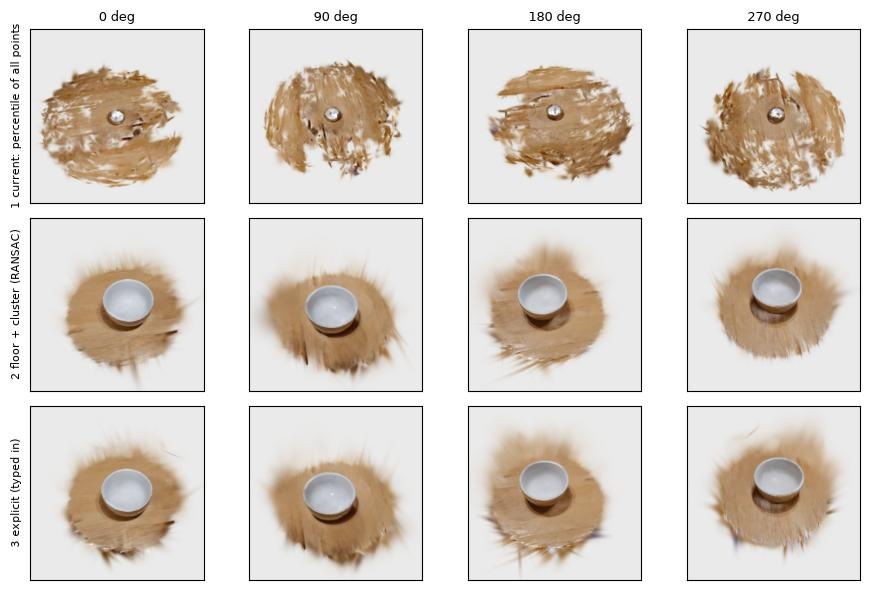

In [9]:
from hurobo.scan import crop_ply
from hurobo.splat import render_splat_orbit
from hurobo.utils.plotting import plot_image_grid

crop_dir = ROOT / "data/scans/sweeps/bowl_1angle/crops"
crop_dir.mkdir(exist_ok=True)
renders = {}
for label, cylinder in methods.items():
    cropped_ply = crop_dir / (label.split(":")[0].split(" (")[0].replace(" ", "_") + ".ply")
    crop_ply(sweep_result.ply_path, cropped_ply, [cylinder])
    renders[label] = render_splat_orbit(cropped_ply, num_views=4, image_size=224, elevation_deg=55)
plot_image_grid(renders, column_titles=["0 deg", "90 deg", "180 deg", "270 deg"])

### What the three methods show
- **Current** (percentile of all points): a cylinder 7 to 18 object radii wide, centred about half an object radius off. The bowl is a speck in a floor disc.
- **Floor + cluster**: about 2.2 object radii, centred within 0.1 to 0.2 object radii of the reference. Its crop looks like the hand-typed one.
- **Limits.** One object in one room, and the reference needs a white object. The crop still carries a rim of floor, and it assumes a dominant floor plane with the object near the middle of the orbit; otherwise `choose_object_crop` falls back to the current fit.

## End to end through the script
Both clips run through `scripts/09_scan_object.py` with its new defaults (`SfmReconstructor.robust()`, floor + cluster crop, `--holdout-every 10`):

```bash
uv run python scripts/09_scan_object.py data/raw/setup_01/bowl_1angle.mp4 --name bowl_1angle_v2 --holdout-every 10
uv run python scripts/09_scan_object.py data/raw/setup_01/bowl_3angle.mp4 --name bowl_3angle_v2 --holdout-every 10
```

| clip | SfM | held-out PSNR | crop |
|---|---|---|---|
| 1-angle | 120/120, 1 model, 87 s | 31.9 dB | floor + cluster, radius 2.74 |
| 3-angle | sequential 70/120 in 3 models, then exhaustive retry 120/120, 447 s | 27.8 dB | floor + cluster, radius 2.17 |

Below, each splat before (`_full`) and after the crop, rendered from 55 degrees at four azimuths.

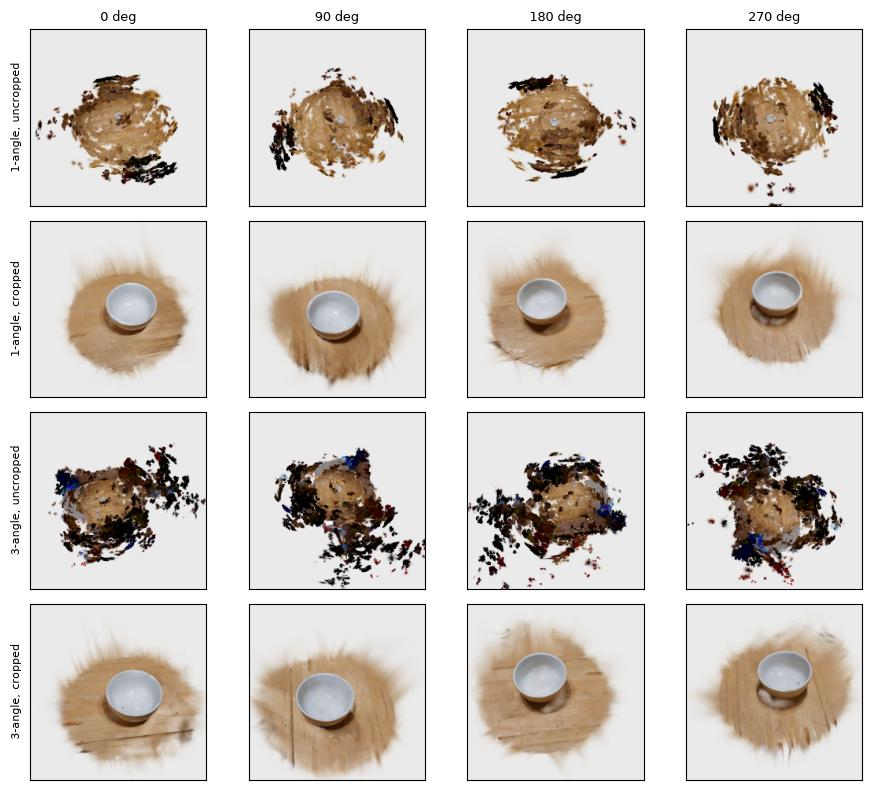

In [10]:
from hurobo.utils.notebook import existing_paths

script_splats = existing_paths(
    {
        "1-angle, uncropped": ROOT / "data/splats/bowl_1angle_v2_full.ply",
        "1-angle, cropped": ROOT / "data/splats/bowl_1angle_v2.ply",
        "3-angle, uncropped": ROOT / "data/splats/bowl_3angle_v2_full.ply",
        "3-angle, cropped": ROOT / "data/splats/bowl_3angle_v2.ply",
    },
    hint="run scripts/09_scan_object.py on bowl_1angle.mp4 and bowl_3angle.mp4 (commands above)",
)
script_renders = {
    label: render_splat_orbit(path, num_views=4, image_size=224, elevation_deg=55)
    for label, path in script_splats.items()
}
plot_image_grid(script_renders, column_titles=["0 deg", "90 deg", "180 deg", "270 deg"])

## The bowl alone, ready for LIBERO
The cropped splats above still contain the floor under and around the bowl. `extract_object_splat` cuts the object off it:

1. keep the Gaussians inside the crop cylinder that are not almost transparent,
2. drop everything within 3 sigma of the floor level (the scatter is measured on the Gaussians),
3. keep the largest connected blob, which discards floaters,
4. rotate the floor normal onto +z and put the floor at z = 0 under the blob's centre.

The result is an upright object with its base on z = 0, which is what `SplatFit.MATCH_BODY_XY` attaches to a LIBERO body (its scale is arbitrary, so it is fitted to the body). The script writes it as `<name>_object.ply`.

Below, the extraction is applied for **each of the three crop methods** on the same splat, then rendered alone and inside LIBERO.

In [11]:
from dataclasses import asdict

import pandas as pd

from hurobo.scan_crop import extract_object_splat

object_dir = ROOT / "data/scans/sweeps/bowl_1angle/objects"
object_dir.mkdir(exist_ok=True)
object_plys, summaries = {}, {}
for label, cylinder in methods.items():
    object_plys[label] = object_dir / (label.split(":")[0].split(" (")[0].replace(" ", "_") + "_object.ply")
    summaries[label] = asdict(
        extract_object_splat(sweep_result.ply_path, object_plys[label], estimate.floor, cylinder)
    )
pd.DataFrame(summaries).T.round(2).assign(**{"reference radius": round(reference.radius, 2)})

,num_gaussians,cut_height,footprint_radius,height,tilt_removed_deg,reference radius
1 current: percentile of all points,9142.0,0.19,1.26,1.21,1.11,1.22
2 floor + cluster (RANSAC),10443.0,0.13,1.22,1.21,1.11,1.22
3 explicit (typed in),10416.0,0.13,1.22,1.21,1.11,1.22


### Each method's bowl, alone
Rendered from 35 degrees at four azimuths, on a neutral background. All three give a complete bowl, and the footprint radius is within about 5 % of the white-pixel reference. The result of the `current` crop is the most ragged (dark patches inside): its cylinder is several times wider, so more haze above the floor links into the blob. The floor cut and the largest-blob step do most of the work, which is why the three look much closer here than the crops did before this step.

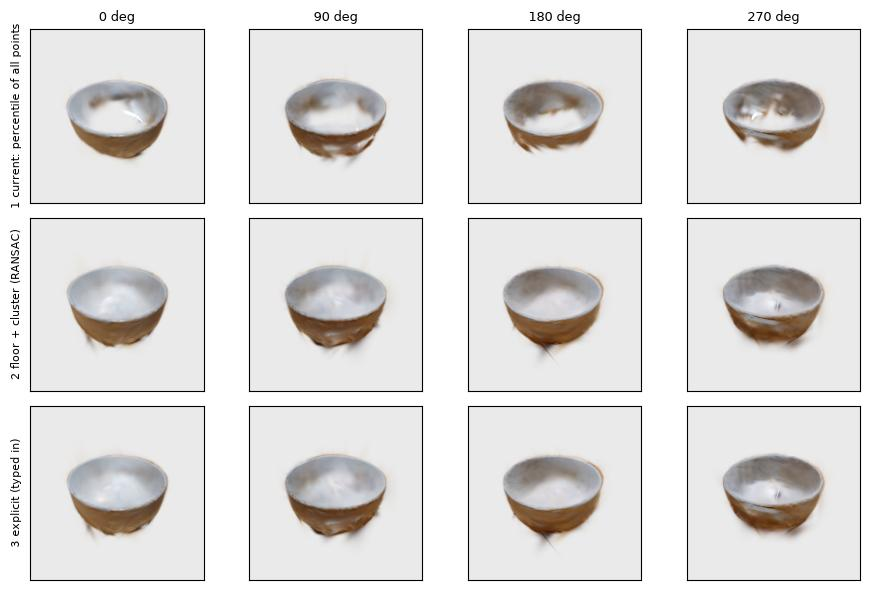

In [12]:
object_renders = {
    label: render_splat_orbit(path, num_views=4, image_size=224, elevation_deg=35)
    for label, path in object_plys.items()
}
plot_image_grid(object_renders, column_titles=["0 deg", "90 deg", "180 deg", "270 deg"])

### Inside LIBERO
Each object splat attached to LIBERO's bowl body (`akita_black_bowl_1_main`, `MATCH_BODY_XY`), composited with the mesh robot by depth. The table and plate are the DISCOVERSE stand-ins, so only the bowl changes between panels. The last two panels are the object-only splats the script wrote for each clip.

In [13]:
%%capture
# (capture hides robosuite's startup logging)
from hurobo.splat import render_bowl_composites

libero_bowls = {
    **object_plys,
    "script, 1-angle": ROOT / "data/splats/bowl_1angle_v2_object.ply",
    "script, 3-angle": ROOT / "data/splats/bowl_3angle_v2_object.ply",
}
composites = render_bowl_composites(libero_bowls, size=384)

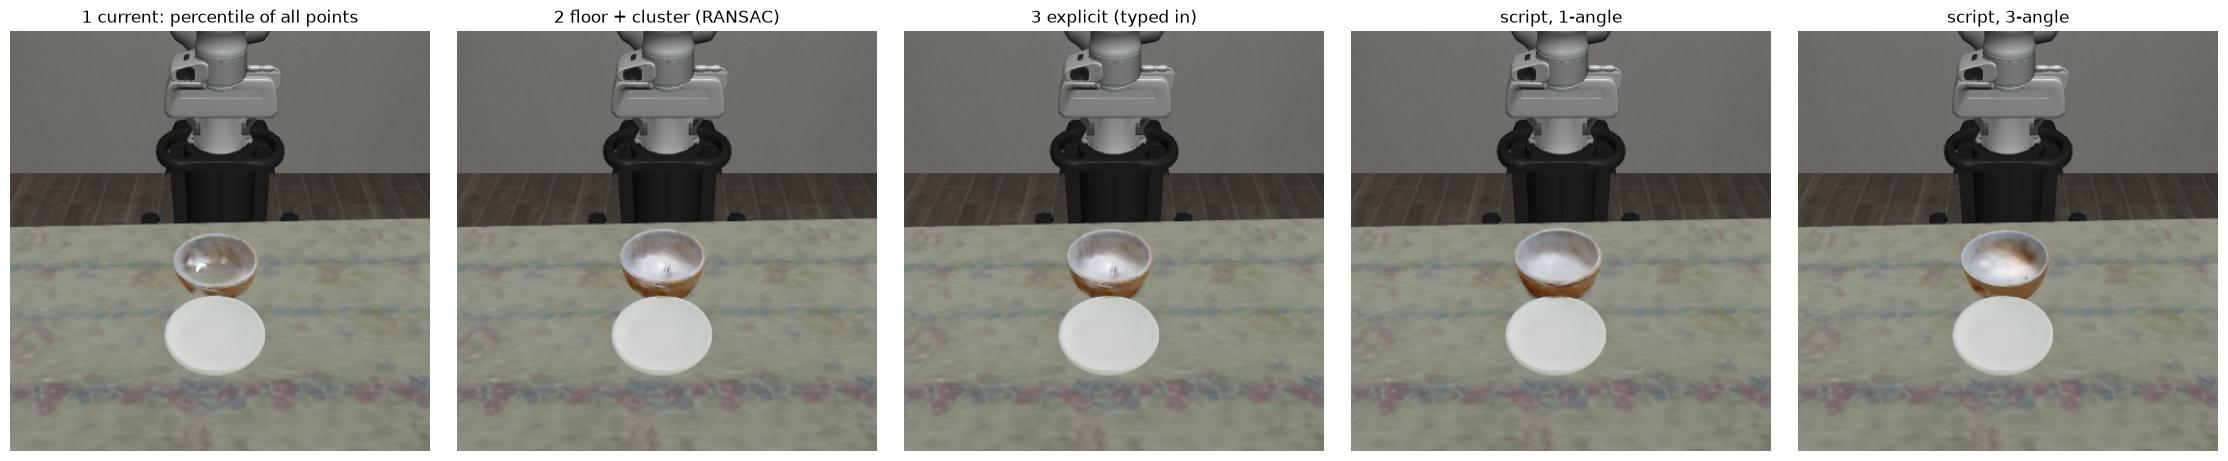

In [14]:
plot_image_row(composites, height_in=4.5)

# Part 2: the new clips: bowl from three heights, the plate, and combinations

Six new phone clips in `data/raw/setup_01/`, same phone and settings as above: the bowl orbited from a **high**, **medium** and **low** camera height, and the **plate** from low down. Each clip is scanned alone with five configs (`default_clip_sweep`), and the bowl clips are also scanned **together** in one COLMAP model (`combined_clip_sweep`: exhaustive matching, 60 keyframes per clip), because a single height never sees every side of a bowl.

- **Modules:** `hurobo.scan_sweep` (`load_labelled`, `extract_result_objects`, `white_object_residuals`), `hurobo.scan_crop`, `hurobo.splat` (`render_asset_composites`)
- **Data:** real clips, not committed. To redo (about 3 h on a laptop GPU; SfM is cached):
  `uv run python scripts/15_scan_clips.py`
- **Same protocol as above:** one run per config, one seed, 7000 iterations, every 10th registered keyframe withheld.


In [15]:
from hurobo.scan_sweep import (
    extract_result_object,
    extract_result_objects,
    load_labelled,
    sweep_table,
    white_object_residuals,
)

CLIPS = ROOT / "data/scans/clips"
SETS = [
    "bowl_high",
    "bowl_med",
    "bowl_low",
    "plate",
    "bowl_high_low",
    "bowl_high_med",
    "bowl_med_low",
    "bowl_high_med_low",
]
clip_results = load_labelled({name: CLIPS / name for name in SETS})
by_label = {r.config.name: r for r in clip_results}
columns = [
    "config",
    "frames",
    "registered",
    "orbit covered (deg)",
    "models",
    "SfM points",
    "reproj (px)",
    "train PSNR (dB)",
    "held-out PSNR (dB)",
    "SfM (s)",
    "train (s)",
]
sweep_table(clip_results)[columns].set_index("config")

,frames,registered,orbit covered (deg),models,SfM points,reproj (px),train PSNR (dB),held-out PSNR (dB),SfM (s),train (s)
config,,,,,,,,,,
bowl_high/colmap_defaults,120,47/120,208,3,3545,0.40,35.2,32.1,15,142
bowl_high/robust_sequential,120,120/120,349,1,16577,0.65,30.9,29.7,73,142
bowl_high/robust_exhaustive,120,120/120,349,1,23606,0.74,31.0,29.4,340,164
bowl_high/robust_exhaustive_60f,60,60/60,339,1,9489,0.68,31.9,29.1,91,160
bowl_med/colmap_defaults,120,27/120,128,6,2581,0.36,37.4,31.5,16,99
bowl_med/robust_sequential,120,120/120,349,1,17355,0.66,33.4,31.9,77,104
bowl_med/robust_exhaustive,120,120/120,349,1,23034,0.73,34.0,31.9,376,108
bowl_med/robust_exhaustive_60f,60,60/60,341,1,8297,0.70,33.7,29.9,93,101
bowl_low/colmap_defaults,120,4/120,13,1,74,0.44,39.6,25.9,6,80


## Registration and PSNR, all sets
COLMAP's defaults fail on every new clip (4 to 63 of 120 keyframes) and the robust settings register all or all but one. As before, read registration and coverage before PSNR. The combined scans have the *lowest* held-out PSNR because their withheld views span three heights, so they are harder; PSNR is not comparable between a single clip and a combination.


In [16]:
from hurobo.utils.viewer import sweep_figure

sweep_figure(clip_results, title="New clips: registration, coverage, PSNR").show()

## Held-out views (photo left, splat right)
The robust exhaustive config for each single clip, and the combined scans.


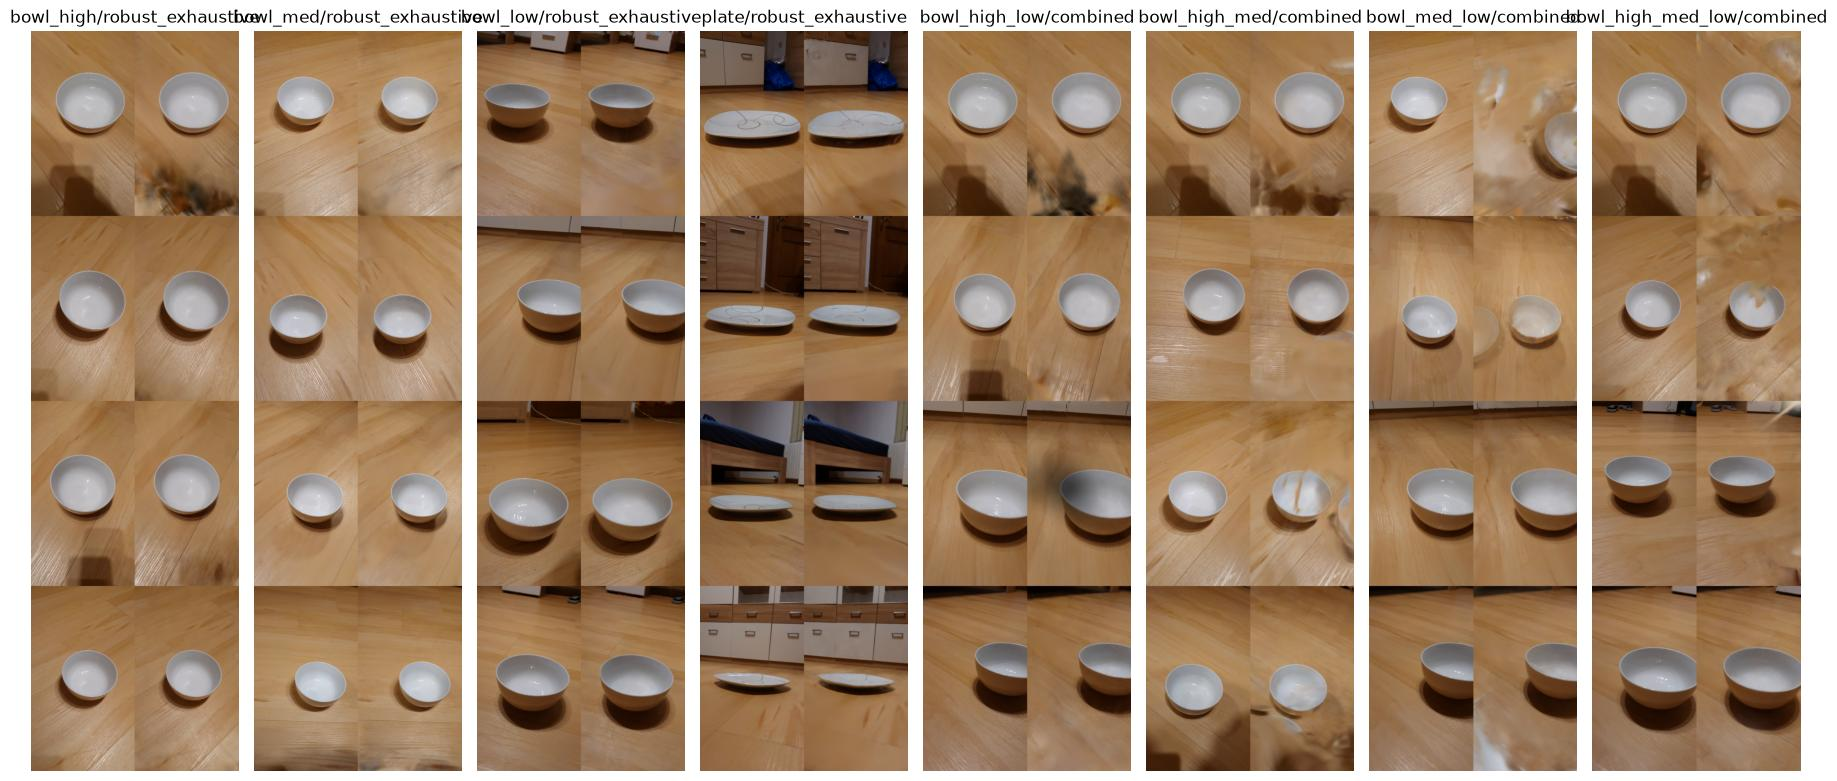

In [17]:
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

from hurobo.utils.plotting import plot_image_row

set_matplotlib_formats("jpeg")
shown = [f"{s}/robust_exhaustive" for s in SETS[:4]] + [f"{s}/combined" for s in SETS[4:]]
plot_image_row({n: plt.imread(by_label[n].preview_path) for n in shown}, height_in=8)

## The object alone, for every reconstruction that registered
`extract_result_objects` applies the pipeline's own crop (floor RANSAC + cluster, then `extract_object_splat`) to each stored splat. Reconstructions with under 80 % of keyframes are skipped; the plate is reported separately below.


In [18]:
objects, skipped = extract_result_objects(clip_results, CLIPS / "_objects")
for name, why in skipped.items():
    print(f"skipped {name}: {why}")

skipped bowl_high/colmap_defaults: only 39 % of keyframes registered
skipped bowl_med/colmap_defaults: only 22 % of keyframes registered
skipped bowl_low/colmap_defaults: only 3 % of keyframes registered
skipped plate/colmap_defaults: only 52 % of keyframes registered
skipped plate/robust_sequential: no Gaussians stand above the floor inside the crop


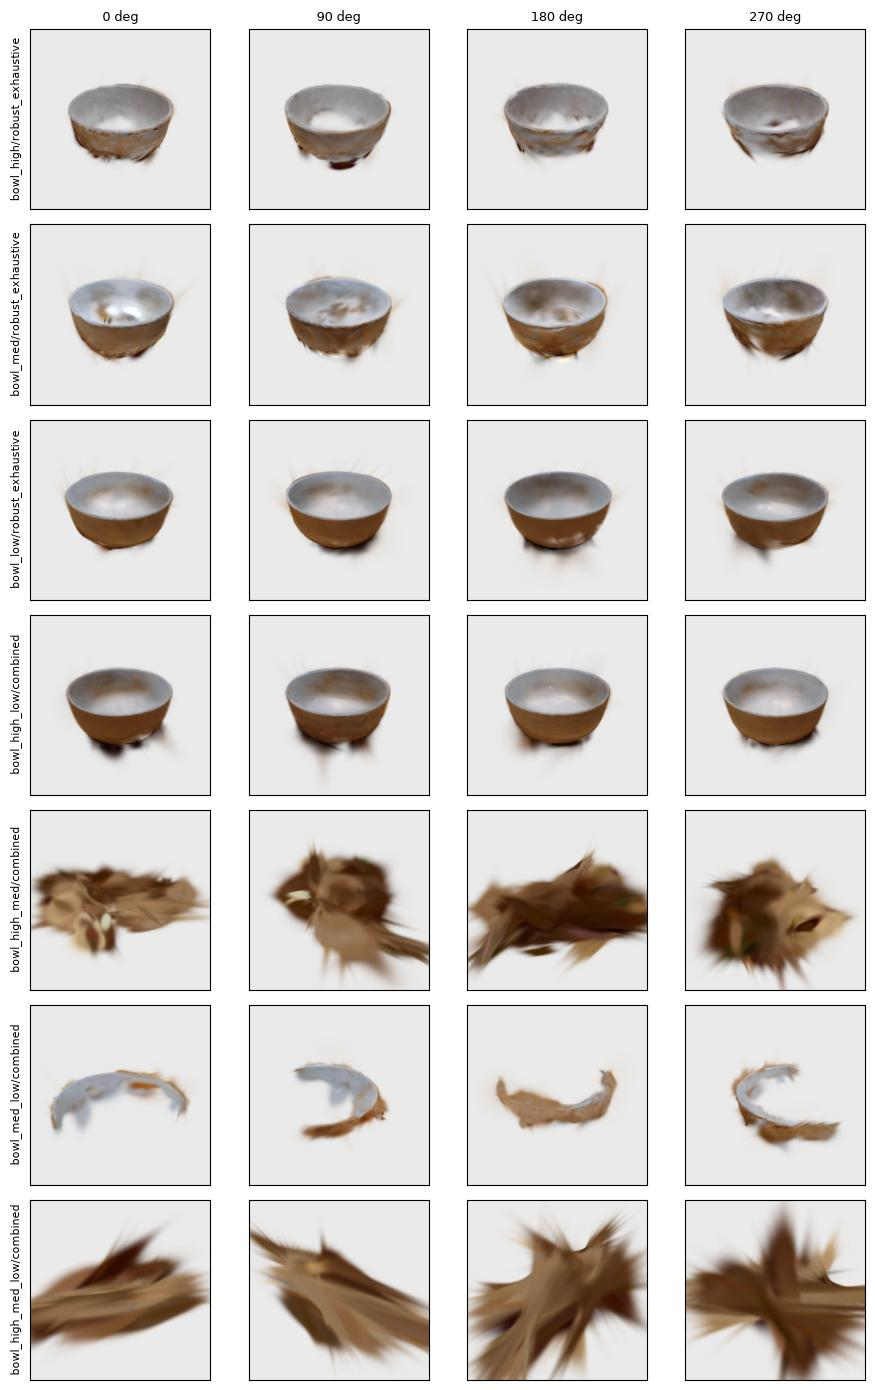

In [19]:
from hurobo.splat import render_splat_orbit
from hurobo.utils.plotting import plot_image_grid

bowl_view = [
    n for n in objects if n.startswith("bowl") and n.split("/")[1] in {"robust_exhaustive", "combined"}
]
bowl_renders = {
    n: render_splat_orbit(objects[n], num_views=4, image_size=224, elevation_deg=30) for n in bowl_view
}
plot_image_grid(bowl_renders, column_titles=["0 deg", "90 deg", "180 deg", "270 deg"])

### Reading the grid
- **One height is not enough, and the single clips differ in how much of the bowl they see.** `bowl_low` gives a clean outer wall but its interior is flatter; `bowl_high` sees the inside but the outside is ragged with a see-through base.
- **High + low is the best bowl here:** a closed, even outer wall and a clean interior, with the floor shadow mostly gone.
- **Every combination that includes the medium clip is broken**, although each registered 120/120 or 180/180 keyframes: the extracted object is a smear or an arc. The single medium clip is fine. The next table shows why.


In [20]:
import pandas as pd

residuals = white_object_residuals(
    [
        by_label[n]
        for n in [
            "bowl_high/robust_exhaustive",
            "bowl_med/robust_exhaustive",
            "bowl_low/robust_exhaustive",
            "bowl_high_low/combined",
            "bowl_high_med/combined",
            "bowl_med_low/combined",
            "bowl_high_med_low/combined",
        ]
    ]
)
residuals.set_index("config")

,white-object radius,mean ray distance,views used
config,,,
bowl_high/robust_exhaustive,1.10,0.12,120/120
bowl_med/robust_exhaustive,1.28,0.20,68/120
bowl_low/robust_exhaustive,0.77,0.05,118/120
bowl_high_low/combined,0.80,0.11,118/119
bowl_high_med/combined,0.80,1.07,93/120
bowl_med_low/combined,0.69,0.80,97/120
bowl_high_med_low/combined,0.75,0.64,157/180


### Why the medium combinations fail
The bowl's white pixels are triangulated from every keyframe, independently of the splat. If the cameras are mutually consistent, those rays meet at one place and the mean ray distance is small. It is 0.05 to 0.20 SfM units for the single clips and for high + low (0.11), and 0.6 to 1.1 for every combination with the medium clip: COLMAP registered all keyframes but the clips do not agree on where the bowl is. **The cause is not established here.** The bowl being nudged between recordings, or the medium clip being tied to the others through the wood grain, would both do it, and I have not checked which. Treat "registered 120/120" as necessary but not sufficient for a combined scan, and check the ray distance.


ObjectSplat(num_gaussians=8605, cut_height=-0.20020451064904107, footprint_radius=1.2036938753566786, height=0.09083461943102715, tilt_removed_deg=2.5364381684260664)


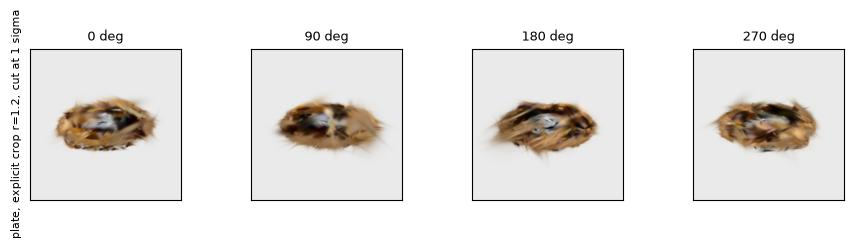

In [21]:
import numpy as np

from hurobo.scan import CropCylinder

plate = by_label["plate/robust_exhaustive"]
plate_crop = CropCylinder(
    1.2, -1e9, 1e9, np.array([-0.04, 0.36])
)  # orbit centre (look-at point); radius read off the renders
plate_ply = CLIPS / "_objects" / "plate__explicit.ply"
plate_info = extract_result_object(plate, plate_ply, crop=plate_crop, height_sigmas=1.0)
print(plate_info)
plot_image_grid(
    {
        "plate, explicit crop r=1.2, cut at 1 sigma": render_splat_orbit(
            plate_ply, num_views=4, image_size=224, elevation_deg=25
        )
    },
    column_titles=["0 deg", "90 deg", "180 deg", "270 deg"],
)

### The plate is a weak result
The plate stands about as high above the floor as the floor's own Gaussian scatter, so the automatic cut at 3 sigma removed most of it (it returned wood-coloured haze). The render above needed a hand-picked crop (the orbit's look-at point, radius 1.2) and a 1-sigma cut, and it is a flat disc with floor-coloured scatter around the rim, not a clean plate. Photos vs splat in the held-out strip look good, so the *scene* reconstructs; it is the cutting-out step that fails for flat objects. Scanning the plate on a coloured cloth, or raised on a block, would be the capture-side fix; I have not tried either.


## Candidates in LIBERO
Chosen from the grid and the ray-distance check:

| candidate | why |
|---|---|
| `bowl_high_low/combined` | best bowl; consistent cameras (ray distance 0.11) |
| `bowl_low/robust_exhaustive` | best single clip, for comparison with the combination |
| `bowl_high/robust_sequential` | the weakest usable single clip, as a floor |
| `plate/robust_exhaustive` (explicit crop) | the only plate scan; weak, see above |

Each is attached to LIBERO's bowl (and plate) body with `MATCH_BODY_XY`, composited with the mesh robot by depth, seen from `agentview` (left) and `frontview` (right). The table is the DISCOVERSE stand-in.


In [22]:
%%capture
from hurobo.splat import build_assets, render_asset_composites


def scene(bowl: str | None = None, plate_ply=None):
    """Asset set for one panel; None keeps the DISCOVERSE stand-in."""
    return build_assets(bowl_ply=objects[bowl] if bowl else None, plate_ply=plate_ply)


libero = render_asset_composites(
    {
        "stand-ins only": scene(),
        "bowl: high+low": scene("bowl_high_low/combined"),
        "bowl: low only": scene("bowl_low/robust_exhaustive"),
        "bowl: high only": scene("bowl_high/robust_sequential"),
        "plate (scan)": scene(plate_ply=plate_ply),
        "bowl high+low, plate scan": scene("bowl_high_low/combined", plate_ply),
    },
    size=320,
    camera_names=("agentview", "frontview"),
)

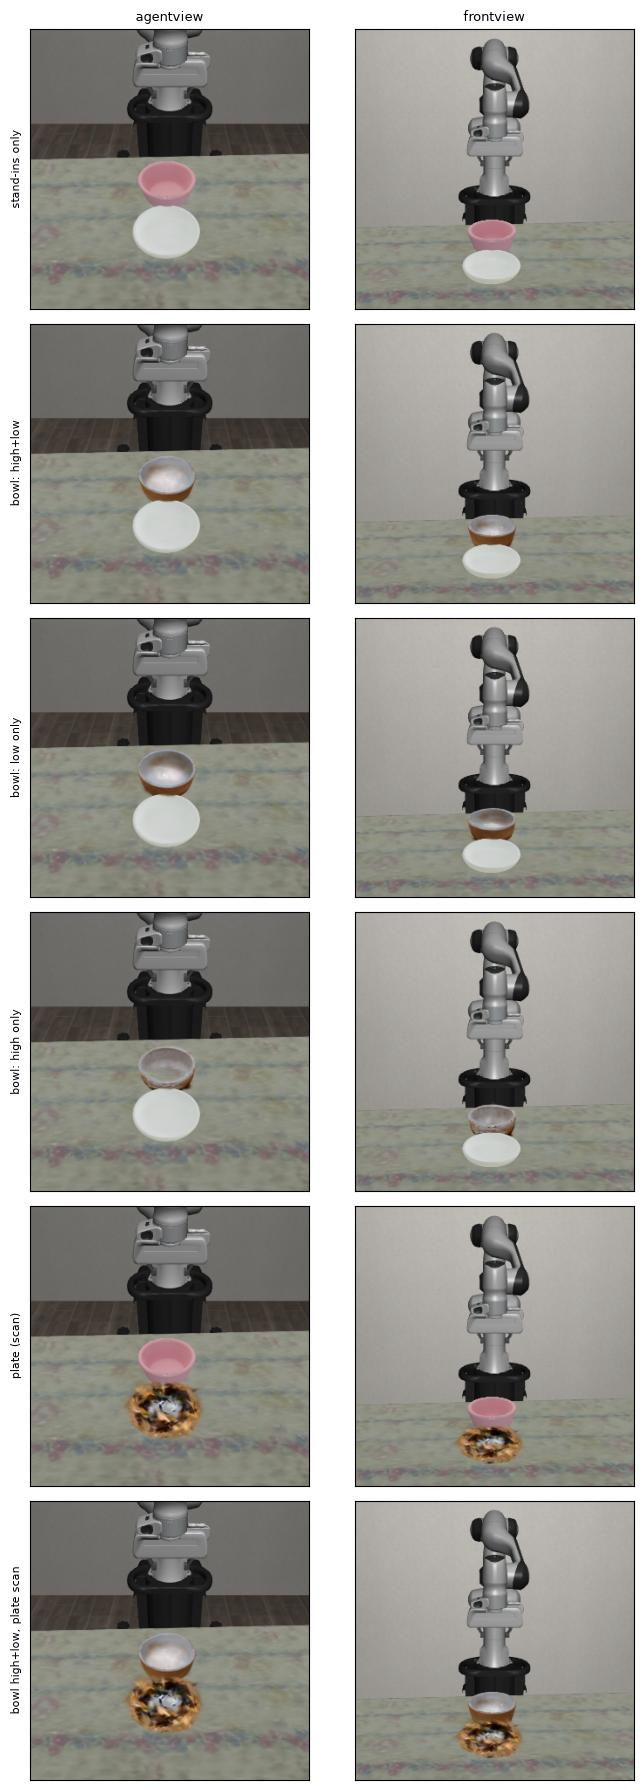

In [23]:
plot_image_grid(
    {k: [v[:, : v.shape[1] // 2], v[:, v.shape[1] // 2 :]] for k, v in libero.items()},
    column_titles=["agentview", "frontview"],
    cell_in=3.0,
)

# Part 3: the plate, second attempt

The first plate clip (above) was filmed too close to the floor: the top face was seen edge-on and the scan came out as a smear. It was re-filmed from three heights, `plate_low`, `plate_med` and `plate_high`, and scanned alone (`plate_low`, `plate_med`) and in combinations (`low+high`, `low+med`) with the same configs as the bowl. `plate_high` was only used inside the combination. Run with `scripts/15_scan_clips.py`.


In [24]:
plate_sets = ["plate", "plate_low", "plate_med", "plate_low_high", "plate_low_med"]
plate_results = load_labelled({name: CLIPS / name for name in plate_sets})
plate_by_label = {r.config.name: r for r in plate_results}
sweep_table(plate_results)[columns].set_index("config")

,frames,registered,orbit covered (deg),models,SfM points,reproj (px),train PSNR (dB),held-out PSNR (dB),SfM (s),train (s)
config,,,,,,,,,,
plate/colmap_defaults,120,63/120,54,2,1278,0.88,34.7,31.8,12,100
plate/robust_sequential,120,120/120,345,1,11489,0.94,33.1,32.0,68,107
plate/robust_exhaustive,120,120/120,333,1,16308,1.01,33.8,32.5,356,108
plate/robust_exhaustive_60f,60,60/60,341,1,7243,0.86,33.8,29.4,90,102
plate_low/colmap_defaults,120,120/120,351,1,25172,0.39,30.1,28.3,51,205
plate_low/robust_sequential,120,120/120,350,1,43395,0.52,30.5,28.5,129,221
plate_low/robust_exhaustive,120,120/120,353,1,53574,0.56,30.8,28.7,463,225
plate_low/robust_exhaustive_60f,60,60/60,348,1,19039,0.53,31.1,27.4,112,202
plate_med/colmap_defaults,120,120/120,351,1,19859,0.48,29.5,28.7,79,176


Registration is not the discriminator any more: all single clips register 120/120, even with COLMAP's defaults. The combinations are the problem. `low+high` links only 71 of 120 keyframes, and `low+med` registers all of them but scores 14.5 dB held-out and the floor plane can no longer be found, so its geometry is inconsistent. Adding clips did not help the plate. Same pattern as the bowl's medium-clip combinations.


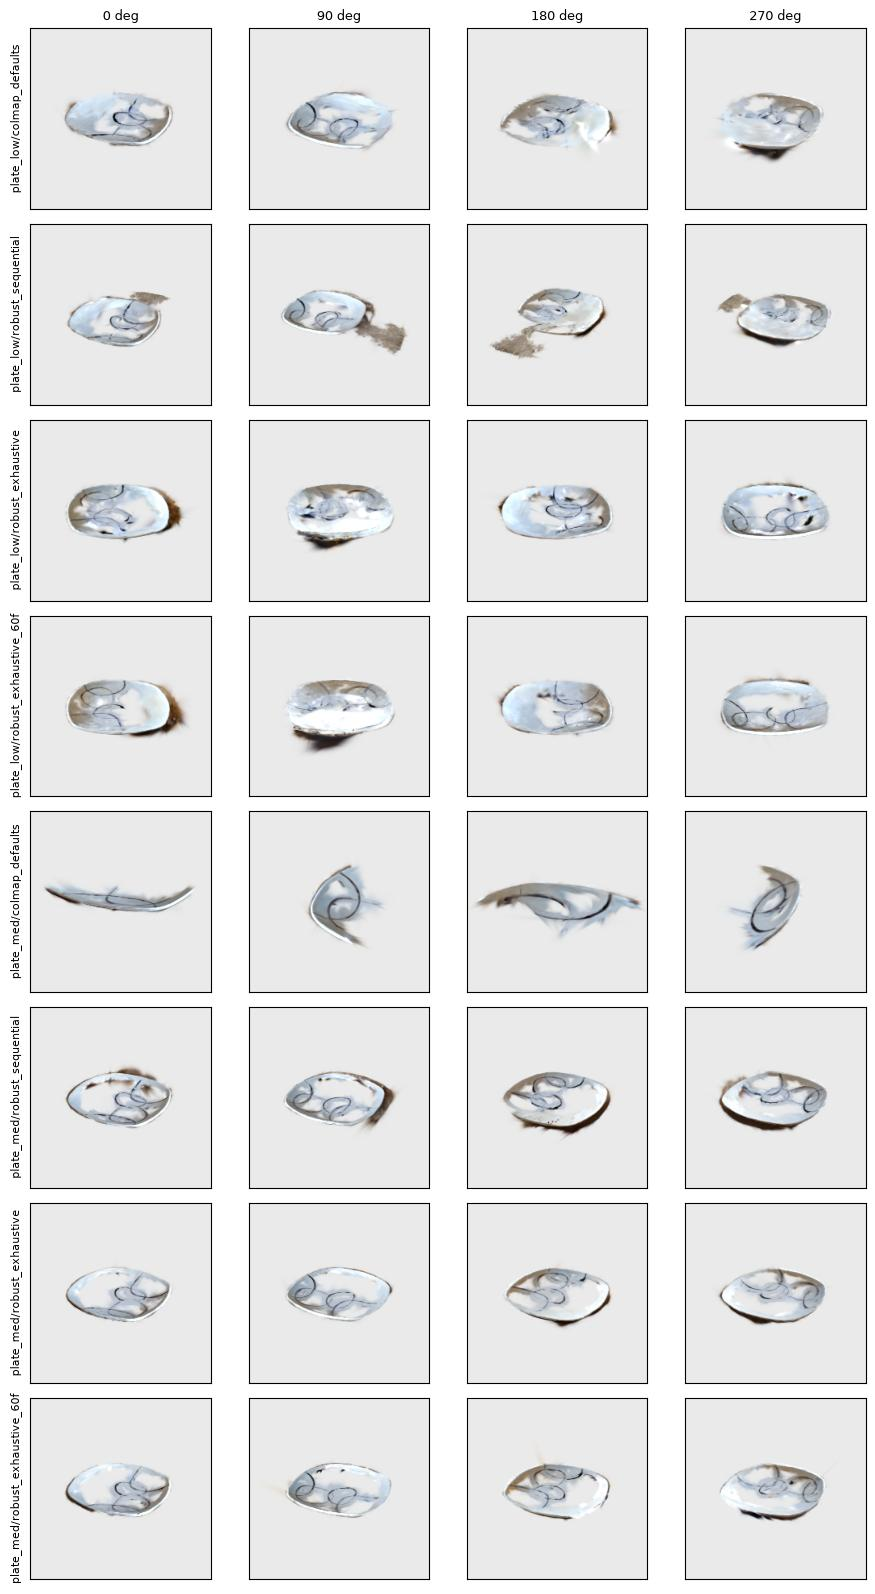

In [25]:
plate_objects, plate_skipped = extract_result_objects(
    [r for r in plate_results if r.config.name.split("/")[0] in {"plate_low", "plate_med"}],
    CLIPS / "_objects",
)
for name, why in plate_skipped.items():
    print(f"skipped {name}: {why}")
plot_image_grid(
    {
        n: render_splat_orbit(ply, num_views=4, image_size=224, elevation_deg=30)
        for n, ply in plate_objects.items()
    },
    column_titles=["0 deg", "90 deg", "180 deg", "270 deg"],
)

### Reading the plate grid
- **`plate_med` is the best plate**: the rim is complete, the interior is even and the printed pattern is legible. `robust_sequential` and `robust_exhaustive` look alike (29.1 dB held-out each), so the 5x faster sequential matching is enough here. `colmap_defaults` gives a broken, folded plate in the medium clip even though it registered every keyframe, another case where registration alone misleads.
- **`plate_low` is usable but worse**: a flatter, patchier top; the sequential config also keeps a patch of floor.
- The automatic crop and the standard 3 sigma cut worked on these clips. No hand-picked crop was needed, unlike the first plate clip.
- Remaining flaws: speckle and a dark rim shadow at the base, and the plate's centre is somewhat washed out. This is better than before, not photoreal.


In [26]:
%%capture
plate_best = plate_objects["plate_med/robust_exhaustive"]
bowl_best = objects["bowl_high_low/combined"]
final = render_asset_composites(
    {
        "stand-ins": build_assets(),
        "scanned plate": build_assets(plate_ply=plate_best),
        "scanned bowl + plate": build_assets(bowl_ply=bowl_best, plate_ply=plate_best),
    },
    size=320,
    camera_names=("agentview", "frontview"),
)

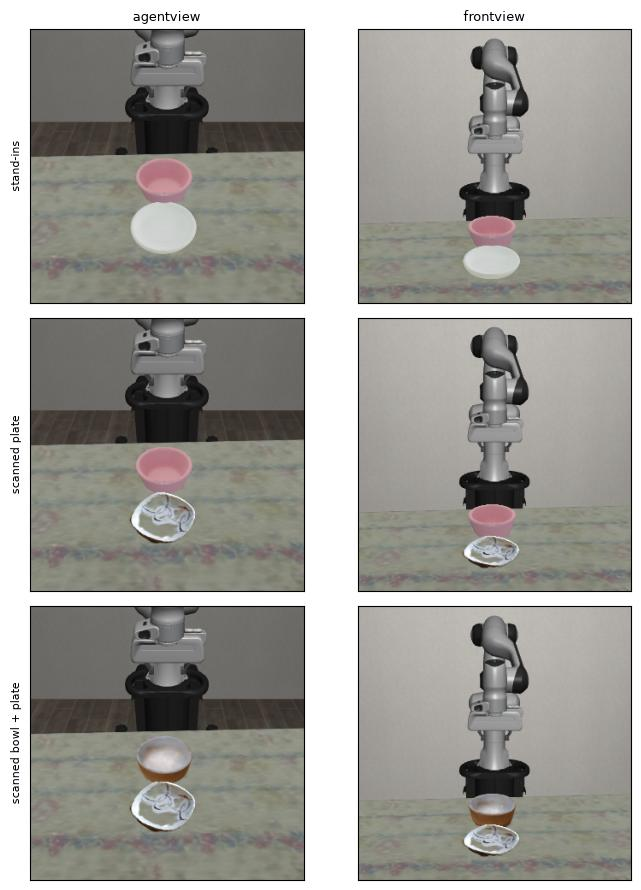

In [27]:
plot_image_grid(
    {k: [v[:, : v.shape[1] // 2], v[:, v.shape[1] // 2 :]] for k, v in final.items()},
    column_titles=["agentview", "frontview"],
    cell_in=3.0,
)

# Part 4: the table and the background, metric, with the ChArUco board on a tablet

Goal: the tabletop and the room behind it as splats in one metric frame, with the plate and the bowl cut out.
The board is shown on a tablet (25 mm squares, 18.6 mm markers, 8 mm thick) lying in the top-left corner of the table;
the measurements are in `data/raw/setup_01/measurements.yaml`. Six table clips were filmed. Before spending SfM time on
a clip, `board_visibility` checks that the board can be detected in it at all (every 15th full-resolution frame).

In [28]:
from dataclasses import asdict

import pandas as pd

from hurobo.camera import ChArUcoCalibrator
from hurobo.scan import board_visibility

RAW = ROOT / "data/raw/setup_01"
board = ChArUcoCalibrator(square_length_m=0.025, marker_length_m=0.0186).board
clips = [
    "tabletop_charuco_mid",
    "tabletop_charuco_topleft",
    "tabletop_charuco_topright",
    "table_scene_zoom_01",
    "table_scene_zoom_02",
    "table_scene_zoom_03",
]
pd.DataFrame([asdict(board_visibility(RAW / f"{c}.mp4", board)) for c in clips]).set_index("video")

,frames_sampled,frames_with_markers,max_markers,max_corners
video,,,,
tabletop_charuco_mid,58,0,0,0
tabletop_charuco_topleft,42,0,0,0
tabletop_charuco_topright,37,0,0,0
table_scene_zoom_01,63,0,0,0
table_scene_zoom_02,57,42,17,24
table_scene_zoom_03,54,40,17,24


**Only `table_scene_zoom_02` and `_03` can be used.** In the other four clips not one of the sampled frames contains a
detectable marker, even at full resolution. In `tabletop_charuco_topleft` the board is about 70 px wide, seen at a grazing
angle, and the tablet renders the white squares cyan, so the markers have almost no contrast. In the two usable clips the
board fills a few hundred pixels and all 17 markers and 24 corners are found in many frames. Capture advice that follows from
this is in `docs/scanning_guide.md` (tablet section).

## Scan: both usable clips in one SfM model, objects cut out automatically
```bash
uv run python scripts/09_scan_object.py data/raw/setup_01/table_scene_zoom_02.mp4 data/raw/setup_01/table_scene_zoom_03.mp4 \
    --name table_zoom_02_03 --charuco --square-length 0.025 --marker-length 0.0186 --board-thickness 0.008 \
    --table-box -0.03 1.415 -0.58 0.02 --find-object plate 0.255 0.028 --find-object bowl 0.138 0.067 --holdout-every 10
```
`--table-box` is the table's rectangle in the board frame (board corner 3 cm from the left edge and 2 cm from the far edge, table
1.445 x 0.60 m). `--find-object` locates each object as a blob above the tabletop and cuts it out with its measured size.

| run | registered | ChArUco corner RMS | held-out PSNR | objects found at (x, y) m |
|---|---|---|---|---|
| `zoom_02` alone | 120/120 | 1.1 mm | 29.5 dB | not cut (blobs at about (0.20, -0.31) and (0.47, -0.31)) |
| `zoom_02` + `zoom_03` | 120/120 | 0.5 mm | 25.6 dB | plate (0.192, -0.303), bowl (0.466, -0.301) |

Both agree on where the objects are. The combined model has the lower held-out PSNR (25.6 against 29.5 dB), which is a
different set of withheld views, not a like-for-like drop; it was not investigated.

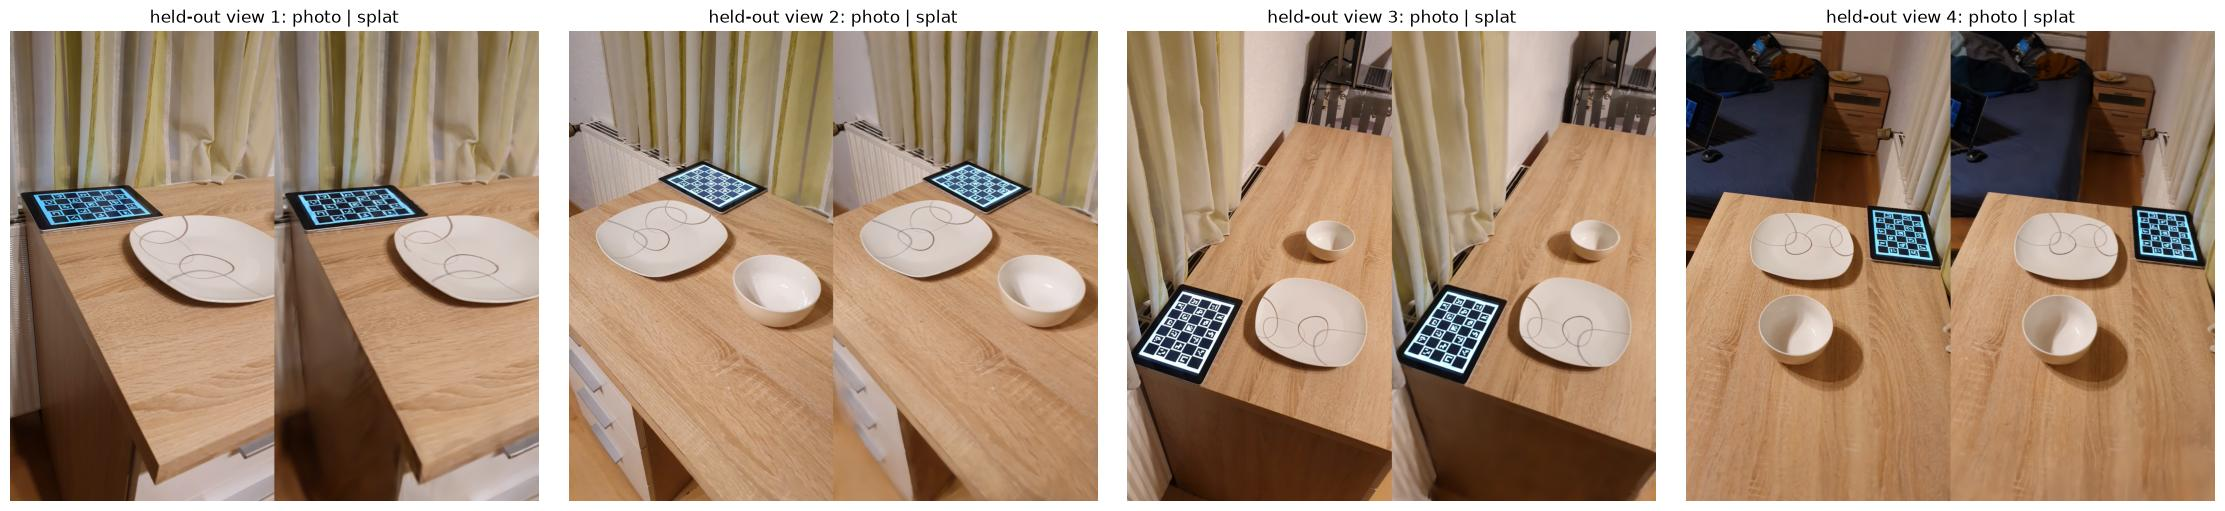

In [29]:
import cv2
import numpy as np

from hurobo.utils.plotting import plot_image_row

TABLE = ROOT / "data/scans/table_zoom_02_03"
preview = cv2.cvtColor(cv2.imread(str(TABLE / "preview_photo_vs_splat.png")), cv2.COLOR_BGR2RGB)
# The script stacks four photo | splat pairs vertically; show them side by side.
pairs = {f"held-out view {i + 1}: photo | splat": tile for i, tile in enumerate(np.array_split(preview, 4))}
plot_image_row(pairs, height_in=5)

## The four splats in 3D
Switch with the dropdown. All four are in the same metric frame: x along the board's 7-square side, y toward the top of the
board image, z up with the **tabletop at z = 0** (the 8 mm tablet offset is applied).

In [30]:
from hurobo.utils.viewer import splat_figure

splat_figure(
    {
        "table (objects removed)": ROOT / "data/splats/table_zoom_02_03_table.ply",
        "background": ROOT / "data/splats/table_zoom_02_03_background.ply",
        "plate": ROOT / "data/splats/table_zoom_02_03_plate.ply",
        "bowl": ROOT / "data/splats/table_zoom_02_03_bowl.ply",
    },
    max_points=8000,
    title="table_zoom_02_03: tabletop, background and the two objects",
).show()

## Rendered (full Gaussians), not just centres

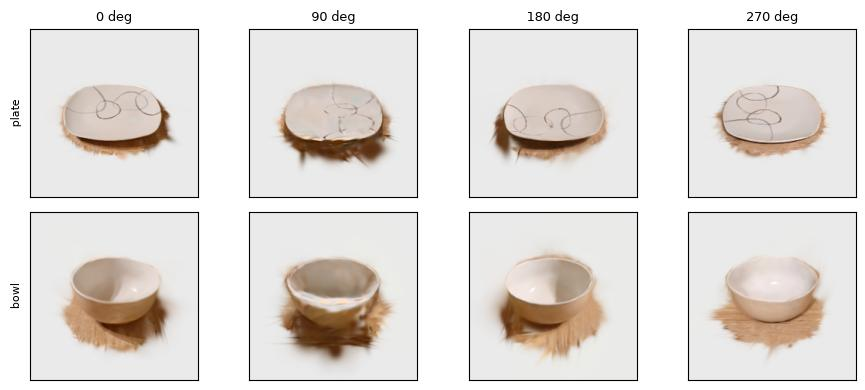

In [31]:
from hurobo.splat import render_splat_orbit
from hurobo.utils.plotting import plot_image_grid
from hurobo.utils.viewer import orbit_figure

splats = ROOT / "data/splats"
orbit_figure(
    render_splat_orbit(splats / "table_zoom_02_03_table.ply", num_views=12, image_size=384, elevation_deg=45),
    title="Tabletop with the objects cut out",
).show()
plot_image_grid(
    {
        name: render_splat_orbit(
            splats / f"table_zoom_02_03_{name}.ply", num_views=4, image_size=224, elevation_deg=35
        )
        for name in ["plate", "bowl"]
    },
    column_titles=["0 deg", "90 deg", "180 deg", "270 deg"],
)

## What this shows, and what it does not
- **Metric scale holds up against a ruler.** With the 25 mm board, a blob of the plate measures about 26 cm across (ruler: 25.5 cm)
  and the bowl about 16 x 14 cm (ruler: 13.8 cm). The blob sizes include the cell size and the rim shading, so this agrees to
  about a centimetre, not a millimetre; the corner RMS is the better number for the board itself.
- **The table is only partly covered.** The clips look at the near-left part of a 1.445 m table. The tabletop splat stops
  where the cameras stopped looking; the box crop does not make up for it. A lap around the whole table is still to be filmed.
- **The object cut leaves holes in the tabletop** under the plate and the bowl, as expected. They were not filled.
- **The objects here are the table scan's own, partial views.** The bowl and plate from the dedicated clips (Parts 2 and 3) are
  more complete; these are what the table scan gives for free, already in the table frame.
- **The finder only works inside the table box.** Without `region_xy` it first picked floaters in the background (plate at
  x = 1.73 m, outside the table); the fix is in `locate_objects_on_table`.
- **One scene, one board position.** The board's tablet thickness (8 mm) and printed sizes come from hand measurements; the
  18.6 mm marker size is derived from the board's 26/35 marker ratio, not measured.

# Part 5: completing the plate with a measured shape prior

Training knobs (30k iterations, a lower densification threshold, D-008) did not close the plate's translucent interior, and the floor cut is not the cause. The plate is a known object: **0.255 m across, 0.028 m high** (`measurements.yaml`). `DishFiller` fits that shape to the extracted splat and

1. drops Gaussians that are not within a few millimetres of the dish surface (haze, floor scatter),
2. adds flat, surface-aligned Gaussians only where no *solid* Gaussian is near the surface,
3. colours them from the nearest bright, low-saturation Gaussians, so brown floor haze and the dark printed pattern are not spread into the gaps.

Assumed, not measured: the flat base is 55 % of the radius and the material is 6 mm thick. The fill is synthetic: the interior it adds is the prior, not the scanned plate.

In [32]:
from hurobo.splat_fill import DishFiller, DishPrior, solid_coverage

prior = DishPrior(diameter_m=0.255, height_m=0.028)  # measurements.yaml: plate
scanned = {
    "plate_med": CLIPS / "_objects" / "plate_med__robust_exhaustive.ply",
    "plate_low": CLIPS / "_objects" / "plate_low__robust_exhaustive.ply",
}
filled, rows = {}, []
for name, ply in scanned.items():
    filled[name] = CLIPS / "_objects" / f"{name}__robust_exhaustive_filled.ply"
    report = DishFiller(prior).fill(ply, filled[name])
    rows.append(
        {
            "clip": name,
            "kept": report.kept,
            "dropped": report.dropped,
            "added": report.added,
            "units per metre": round(report.units_per_metre, 2),
            "solid coverage, scan": round(solid_coverage(ply, report.radius_units), 2),
            "solid coverage, filled": round(solid_coverage(filled[name], report.radius_units), 2),
        }
    )
pd.DataFrame(rows).set_index("clip")

,kept,dropped,added,units per metre,"solid coverage, scan","solid coverage, filled"
clip,,,,,,
plate_med,22445,10625,44313,9.46,0.34,1.00
plate_low,24486,2168,34891,8.36,0.47,0.98


Coverage is the share of the footprint disc whose top-down cells hold solid Gaussians (opacity-composited, at least 0.8). It is a proxy that ignores Gaussian extent, so it rewards the fill by construction: a filled disc will always reach about 1. The renders below are the check that matters.

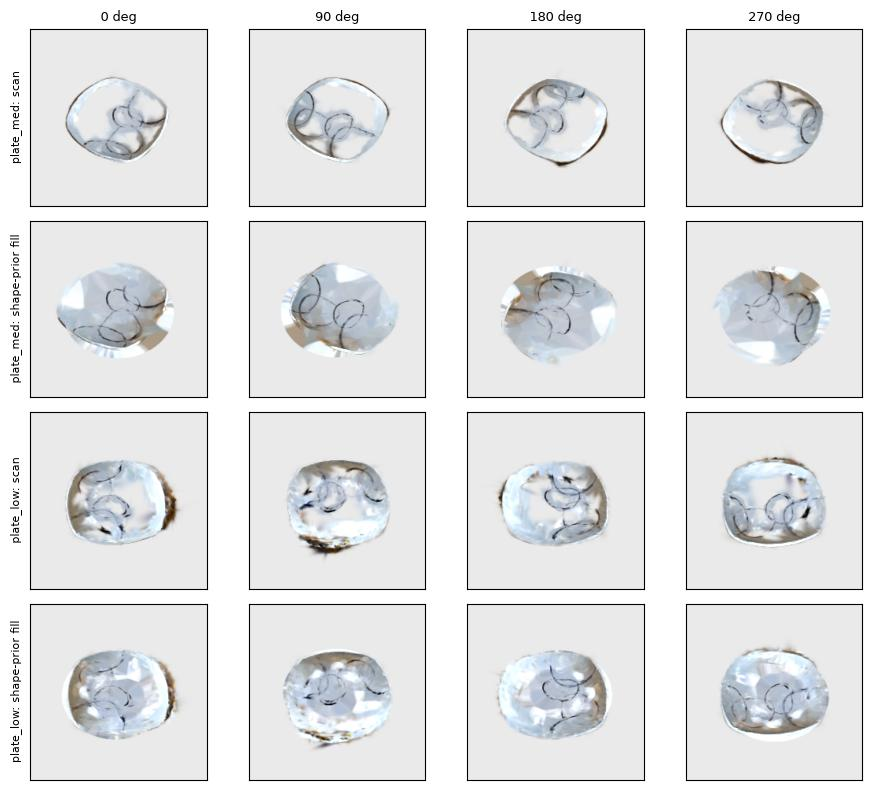

In [33]:
renders = {}
for name in scanned:
    renders[f"{name}: scan"] = render_splat_orbit(
        scanned[name], num_views=4, image_size=224, elevation_deg=55
    )
    renders[f"{name}: shape-prior fill"] = render_splat_orbit(
        filled[name], num_views=4, image_size=224, elevation_deg=55
    )
plot_image_grid(renders, column_titles=["0 deg", "90 deg", "180 deg", "270 deg"])

### What the fill shows (and what it does not)

- **The interior is closed and the printed pattern is kept**, because the scan's own Gaussians stay wherever they are solid and on the surface; only gaps are filled.
- **The shape is the prior's, not the scan's.** The warped, squarish rim of the scan is replaced by a circle of the measured diameter, and the dish profile (flat base, linear rise) is assumed. Do not read the filled rim as a measurement.
- **Facets are visible** in the filled areas: each synthetic Gaussian takes the local colour, and gloss and shading baked into the scan are not reproduced. A learned depth prior or a glossy-surface method (see the review in the design log) would be the principled alternative; this is the cheap, deterministic one.
- **Checked on two clips of one plate** by eye, with a coverage proxy. No held-out photometric comparison: the fill is not trained, so PSNR against photos is a separate experiment.